# 03 — Diễn giải luật kết hợp và ôn bảo vệ

## Cách học notebook này
Chạy Notebook 1 → 2 trước. Sau đó Restart Kernel → Run All cho notebook này. Đọc mục 1 để hiểu cách chọn luật, mục 2 để học từng luật, mục 3 để tính tay và mục 6 để luyện trả lời.

Mục tiêu là trình bày một số luật dễ hiểu cùng số khách làm căn cứ. Luật được khai phá trên toàn bộ dữ liệu hiện có, chưa kiểm chứng trên dữ liệu ngoài. Dấu → diễn đạt luật kết hợp, không chứng minh nguyên nhân hay diễn biến theo thời gian.

Notebook tạo bảng 7 luật, 3 hình và một báo cáo Markdown có số liệu, giải thích và câu hỏi ôn tập tại `reports/apriori/apriori_report_and_study_guide.md`.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

%matplotlib inline
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv").is_file()), None)
assert ROOT is not None
DATA_DIR = ROOT / "data/processed/apriori"
REPORT_DIR = ROOT / "reports/apriori"
TABLE_DIR = REPORT_DIR / "tables"
FIG_DIR = REPORT_DIR / "figures"
run = json.loads((DATA_DIR / "apriori_run_metadata.json").read_text(encoding="utf-8"))
cleaning = json.loads((DATA_DIR / "cleaning_metadata.json").read_text(encoding="utf-8"))
assert run["clean_sha256"] == cleaning["clean_sha256"]
assert hashlib.sha256((DATA_DIR / "telco_clean.csv").read_bytes()).hexdigest() == run["clean_sha256"]
assert hashlib.sha256((ROOT / cleaning["source"]).read_bytes()).hexdigest() == cleaning["source_sha256"]
clean = pd.read_csv(DATA_DIR / "telco_clean.csv")
transactions = pd.read_csv(DATA_DIR / "transactions_categorical.csv")
assert len(clean) == len(transactions) == run["rows"]
expected = clean[run["transaction_columns"][:12]].copy()
expected["TenureGroup"] = pd.cut(clean["tenure"], [-np.inf,12,24,48,np.inf],
                                labels=run["binning"]["tenure"]["labels"]).astype(str)
expected["MonthlyChargesGroup"] = pd.cut(
    clean["MonthlyCharges"], run["binning"]["monthly_charges"]["edges"],
    labels=run["binning"]["monthly_charges"]["labels"], include_lowest=True).astype(str)
expected["Churn"] = clean["Churn"]
pd.testing.assert_frame_equal(transactions, expected)
N = len(clean)
BASE = clean["Churn"].eq("Yes").mean()
assert np.isclose(BASE, run["base_churn_rate"])

def load_rules(filename):
    table = pd.read_csv(TABLE_DIR / filename)
    for column in ["antecedents", "consequents"]:
        table[column] = table[column].map(lambda s: frozenset(json.loads(s)))
    assert table["rule_key"].is_unique
    return table

def customers_matching(antecedents):
    mask = pd.Series(True, index=transactions.index)
    for item in antecedents:
        column, value = item.split("=", 1)
        mask &= transactions[column].eq(value)
    return mask

all_05 = load_rules("apriori_target_all_support_05.csv")
rules_05 = load_rules("apriori_selected_support_05.csv")
qualified_10 = load_rules("apriori_qualified_support_10.csv")
selected_10 = load_rules("apriori_selected_support_10.csv")
assert set(rules_05["rule_key"]) == set(all_05.loc[all_05["selected"], "rule_key"])
assert len(rules_05) == run["sensitivity"][0]["n_selected"]
assert len(selected_10) == run["sensitivity"][1]["n_selected"]
for row in rules_05.itertuples():
    mask = customers_matching(row.antecedents)
    a = int(mask.sum())
    ac = int((mask & transactions["Churn"].eq("Yes")).sum())
    assert (a, ac) == (row.n_antecedent, row.n_churn_in_group)
    assert np.allclose([row.support, row.confidence, row.lift], [ac/N,ac/a,(ac/a)/BASE])
    assert row.consequents == frozenset({"Churn=Yes"})
print(f"Đã đối chiếu {len(rules_05)} luật được giữ với {N:,} khách hàng.")
plt.rcParams.update({"font.family":"DejaVu Sans", "figure.dpi":110})

Đã đối chiếu 261 luật được giữ với 7,043 khách hàng.


## 1. Chọn 7 luật theo mục đích trình bày

Ba luật đầu là các nhóm đơn giản về hợp đồng, thời gian sử dụng và thanh toán. Luật 4 kết hợp hai dịch vụ. Ba luật sau mở rộng sang dịch vụ Internet, phí tháng và tổ hợp hợp đồng/dịch vụ/thanh toán.

Đây là lựa chọn biên tập từ các luật đã đạt ngưỡng và qua lọc dư thừa ở Notebook 2. Không tuyên bố đây là 7 luật tốt nhất theo mọi tiêu chí. Không chọn chỉ theo lift: còn xem độ dài, số khách và chủ đề.

Một số tiền đề chứa nhau có chủ đích để học cách so sánh nhóm rộng với nhóm hẹp. Chúng không phải 7 phân khúc tách biệt. Nếu chạy lại dữ liệu mà luật đã chọn không còn đạt điều kiện, notebook dừng để xem lại lựa chọn.

In [2]:
choices = [
    ("R1", "Hợp đồng theo tháng", {"Contract=Month-to-month"},
     "Một điều kiện dễ hiểu, nhóm lớn, nối trực tiếp với EDA.",
     "Khảo sát lý do lựa chọn hợp đồng ngắn và mức hài lòng; cân nhắc thử nghiệm ưu đãi gia hạn tự nguyện.",
     "Khách chưa hài lòng có thể tự chọn hợp đồng ngắn; chưa chứng minh đổi hợp đồng sẽ giảm churn."),
    ("R2", "Sử dụng trong 12 tháng đầu", {"TenureGroup=0-12"},
     "Minh họa nhóm thời gian và nhu cầu tìm hiểu giai đoạn đầu sử dụng.",
     "Khảo sát trải nghiệm đăng ký, lắp đặt và sử dụng ban đầu của nhóm tenure ngắn.",
     "Tenure là thời lượng trong ảnh chụp dữ liệu, chưa cung cấp lịch sử theo dõi từng khách."),
    ("R3", "Thanh toán bằng Electronic check", {"PaymentMethod=Electronic check"},
     "Một chủ đề thanh toán, không lặp nguyên luật hợp đồng.",
     "Khảo sát khó khăn và mức hài lòng với phương thức thanh toán; tìm hiểu lựa chọn thanh toán khác.",
     "Phương thức thanh toán có thể đi kèm loại hợp đồng hoặc thời gian sử dụng; chưa xác định nguyên nhân."),
    ("R4", "Không bảo mật trực tuyến và không hỗ trợ kỹ thuật",
     {"OnlineSecurity=No", "TechSupport=No"},
     "Minh họa kết hợp hai điều kiện dịch vụ.",
     "Khảo sát nhu cầu hỗ trợ và bảo mật, kiểm tra chất lượng phục vụ trước khi đề xuất gói bổ sung.",
     "Không đăng ký dịch vụ không đồng nghĩa đã gặp sự cố; chưa chứng minh mua thêm dịch vụ ngăn churn."),
    ("R5", "Cáp quang trong 12 tháng đầu", {"InternetService=Fiber optic", "TenureGroup=0-12"},
     "Nhóm hẹp mở rộng R2, cho phép so sánh churn của nhóm con với nhóm rộng.",
     "Khảo sát trải nghiệm lắp đặt, chất lượng và kỳ vọng của khách cáp quang có tenure ngắn.",
     "Nhóm con của R2; chênh lệch chưa kiểm soát hợp đồng, mức phí hay các yếu tố đồng thời."),
    ("R6", "Phí tháng cao và không hỗ trợ kỹ thuật",
     {"MonthlyChargesGroup=High", "TechSupport=No"},
     "Đưa biến phí đã rời rạc hóa vào ví dụ kết hợp dịch vụ; giảm trùng lặp với R7.",
     "Tìm hiểu giá trị cảm nhận, nhu cầu hỗ trợ và khả năng chi trả của nhóm này.",
     "High là nhóm phí trên phân vị 2/3 của mẫu, không phải chuẩn phí cao của ngành."),
    ("R7", "Hợp đồng tháng, cáp quang, Electronic check",
     {"Contract=Month-to-month", "InternetService=Fiber optic", "PaymentMethod=Electronic check"},
     "Tổ hợp ba khía cạnh hợp đồng, dịch vụ và thanh toán có số khách đáng kể.",
     "Khảo sát đồng thời chất lượng dịch vụ, điều khoản hợp đồng và quy trình thanh toán.",
     "Chồng lấn R1/R3 và có thể chồng lấn các luật khác; không cộng số khách giữa các luật."),
]
picked = []
for rule_id, title, items, reason, suggestion, limitation in choices:
    match = rules_05.loc[rules_05["antecedents"].map(lambda s: s == frozenset(items))]
    assert len(match) == 1, f"Cần xem lại luật {rule_id}: {title}"
    row = match.iloc[0].to_dict()
    row.update(rule_id=rule_id, title=title, selection_reason=reason,
               suggestion=suggestion, limitation=limitation)
    row["qualified_at_support_10"] = row["rule_key"] in set(qualified_10["rule_key"])
    row["selected_at_support_10"] = row["rule_key"] in set(selected_10["rule_key"])
    row["non_churn_in_group"] = int(row["n_antecedent"] - row["n_churn_in_group"])
    row["antecedent_coverage"] = row["n_antecedent"] / N
    picked.append(row)
featured = pd.DataFrame(picked)
display(featured[["rule_id","title","n_antecedent","n_churn_in_group",
                  "support","confidence","lift","qualified_at_support_10"]].round(4))
print("Tỷ lệ nền:", f"{BASE:.2%}")

,rule_id,title,n_antecedent,n_churn_in_group,support,confidence,lift,qualified_at_support_10
0,R1,Hợp đồng theo tháng,3875,1655,0.2350,0.4271,1.6094,True
1,R2,Sử dụng trong 12 tháng đầu,2186,1037,0.1472,0.4744,1.7876,True
2,R3,Thanh toán bằng Electronic check,2365,1071,0.1521,0.4529,1.7065,True
3,R4,Không bảo mật trực tuyến và không hỗ trợ kỹ thuật,2553,1250,0.1775,0.4896,1.8450,True
4,R5,Cáp quang trong 12 tháng đầu,923,645,0.0916,0.6988,2.6333,False
5,R6,Phí tháng cao và không hỗ trợ kỹ thuật,1370,618,0.0877,0.4511,1.6999,False
6,R7,"Hợp đồng tháng, cáp quang, Electronic check",1307,789,0.1120,0.6037,2.2748,True


Tỷ lệ nền: 26.54%


## 2. Đọc từng luật theo 5 bước

**Luật → số liệu → cách hiểu → gợi ý cần kiểm chứng → hạn chế.**

Trong phần số liệu, support dùng toàn bộ 7.043 khách làm mẫu số; confidence dùng số khách thỏa tiền đề. Lift so sánh confidence với tỷ lệ churn nền. Số người không churn trong nhóm cho thấy luật không đúng tuyệt đối với mọi khách.

In [3]:
narratives = []
for row in featured.itertuples():
    persistence = ("Còn đạt ngưỡng khi tăng support lên 0,10."
                   if row.qualified_at_support_10 else
                   "Không đạt support 0,10; số khách có cả tiền đề và churn chưa tới 10% toàn bộ.")
    text = (
        f"### {row.rule_id} — {row.title}\n\n"
        f"**Luật:** {row.rule_key}\n\n"
        f"**Số liệu:** {int(row.n_antecedent):,} khách thỏa tiền đề; "
        f"{int(row.n_churn_in_group):,} người churn và {int(row.non_churn_in_group):,} người không churn. "
        f"Support = **{row.support:.2%}**, confidence = **{row.confidence:.2%}**, "
        f"lift = **{row.lift:.2f}**.\n\n"
        f"**Cách hiểu:** Trong nhóm này, tỷ lệ churn quan sát là {row.confidence:.2%}, "
        f"bằng {row.lift:.2f} lần tỷ lệ chung {BASE:.2%}. "
        f"Nhóm thỏa tiền đề chiếm {row.antecedent_coverage:.2%} dữ liệu; "
        "tỷ lệ này khác support vì bao gồm cả khách không churn.\n\n"
        f"**Lý do trình bày:** {row.selection_reason}\n\n"
        f"**Gợi ý cần kiểm chứng:** {row.suggestion}\n\n"
        f"**Hạn chế:** {row.limitation} {persistence}\n"
    )
    narratives.append(text)
    display(Markdown(text))

### R1 — Hợp đồng theo tháng

**Luật:** Contract=Month-to-month -> Churn=Yes

**Số liệu:** 3,875 khách thỏa tiền đề; 1,655 người churn và 2,220 người không churn. Support = **23.50%**, confidence = **42.71%**, lift = **1.61**.

**Cách hiểu:** Trong nhóm này, tỷ lệ churn quan sát là 42.71%, bằng 1.61 lần tỷ lệ chung 26.54%. Nhóm thỏa tiền đề chiếm 55.02% dữ liệu; tỷ lệ này khác support vì bao gồm cả khách không churn.

**Lý do trình bày:** Một điều kiện dễ hiểu, nhóm lớn, nối trực tiếp với EDA.

**Gợi ý cần kiểm chứng:** Khảo sát lý do lựa chọn hợp đồng ngắn và mức hài lòng; cân nhắc thử nghiệm ưu đãi gia hạn tự nguyện.

**Hạn chế:** Khách chưa hài lòng có thể tự chọn hợp đồng ngắn; chưa chứng minh đổi hợp đồng sẽ giảm churn. Còn đạt ngưỡng khi tăng support lên 0,10.


### R2 — Sử dụng trong 12 tháng đầu

**Luật:** TenureGroup=0-12 -> Churn=Yes

**Số liệu:** 2,186 khách thỏa tiền đề; 1,037 người churn và 1,149 người không churn. Support = **14.72%**, confidence = **47.44%**, lift = **1.79**.

**Cách hiểu:** Trong nhóm này, tỷ lệ churn quan sát là 47.44%, bằng 1.79 lần tỷ lệ chung 26.54%. Nhóm thỏa tiền đề chiếm 31.04% dữ liệu; tỷ lệ này khác support vì bao gồm cả khách không churn.

**Lý do trình bày:** Minh họa nhóm thời gian và nhu cầu tìm hiểu giai đoạn đầu sử dụng.

**Gợi ý cần kiểm chứng:** Khảo sát trải nghiệm đăng ký, lắp đặt và sử dụng ban đầu của nhóm tenure ngắn.

**Hạn chế:** Tenure là thời lượng trong ảnh chụp dữ liệu, chưa cung cấp lịch sử theo dõi từng khách. Còn đạt ngưỡng khi tăng support lên 0,10.


### R3 — Thanh toán bằng Electronic check

**Luật:** PaymentMethod=Electronic check -> Churn=Yes

**Số liệu:** 2,365 khách thỏa tiền đề; 1,071 người churn và 1,294 người không churn. Support = **15.21%**, confidence = **45.29%**, lift = **1.71**.

**Cách hiểu:** Trong nhóm này, tỷ lệ churn quan sát là 45.29%, bằng 1.71 lần tỷ lệ chung 26.54%. Nhóm thỏa tiền đề chiếm 33.58% dữ liệu; tỷ lệ này khác support vì bao gồm cả khách không churn.

**Lý do trình bày:** Một chủ đề thanh toán, không lặp nguyên luật hợp đồng.

**Gợi ý cần kiểm chứng:** Khảo sát khó khăn và mức hài lòng với phương thức thanh toán; tìm hiểu lựa chọn thanh toán khác.

**Hạn chế:** Phương thức thanh toán có thể đi kèm loại hợp đồng hoặc thời gian sử dụng; chưa xác định nguyên nhân. Còn đạt ngưỡng khi tăng support lên 0,10.


### R4 — Không bảo mật trực tuyến và không hỗ trợ kỹ thuật

**Luật:** OnlineSecurity=No & TechSupport=No -> Churn=Yes

**Số liệu:** 2,553 khách thỏa tiền đề; 1,250 người churn và 1,303 người không churn. Support = **17.75%**, confidence = **48.96%**, lift = **1.85**.

**Cách hiểu:** Trong nhóm này, tỷ lệ churn quan sát là 48.96%, bằng 1.85 lần tỷ lệ chung 26.54%. Nhóm thỏa tiền đề chiếm 36.25% dữ liệu; tỷ lệ này khác support vì bao gồm cả khách không churn.

**Lý do trình bày:** Minh họa kết hợp hai điều kiện dịch vụ.

**Gợi ý cần kiểm chứng:** Khảo sát nhu cầu hỗ trợ và bảo mật, kiểm tra chất lượng phục vụ trước khi đề xuất gói bổ sung.

**Hạn chế:** Không đăng ký dịch vụ không đồng nghĩa đã gặp sự cố; chưa chứng minh mua thêm dịch vụ ngăn churn. Còn đạt ngưỡng khi tăng support lên 0,10.


### R5 — Cáp quang trong 12 tháng đầu

**Luật:** InternetService=Fiber optic & TenureGroup=0-12 -> Churn=Yes

**Số liệu:** 923 khách thỏa tiền đề; 645 người churn và 278 người không churn. Support = **9.16%**, confidence = **69.88%**, lift = **2.63**.

**Cách hiểu:** Trong nhóm này, tỷ lệ churn quan sát là 69.88%, bằng 2.63 lần tỷ lệ chung 26.54%. Nhóm thỏa tiền đề chiếm 13.11% dữ liệu; tỷ lệ này khác support vì bao gồm cả khách không churn.

**Lý do trình bày:** Nhóm hẹp mở rộng R2, cho phép so sánh churn của nhóm con với nhóm rộng.

**Gợi ý cần kiểm chứng:** Khảo sát trải nghiệm lắp đặt, chất lượng và kỳ vọng của khách cáp quang có tenure ngắn.

**Hạn chế:** Nhóm con của R2; chênh lệch chưa kiểm soát hợp đồng, mức phí hay các yếu tố đồng thời. Không đạt support 0,10; số khách có cả tiền đề và churn chưa tới 10% toàn bộ.


### R6 — Phí tháng cao và không hỗ trợ kỹ thuật

**Luật:** MonthlyChargesGroup=High & TechSupport=No -> Churn=Yes

**Số liệu:** 1,370 khách thỏa tiền đề; 618 người churn và 752 người không churn. Support = **8.77%**, confidence = **45.11%**, lift = **1.70**.

**Cách hiểu:** Trong nhóm này, tỷ lệ churn quan sát là 45.11%, bằng 1.70 lần tỷ lệ chung 26.54%. Nhóm thỏa tiền đề chiếm 19.45% dữ liệu; tỷ lệ này khác support vì bao gồm cả khách không churn.

**Lý do trình bày:** Đưa biến phí đã rời rạc hóa vào ví dụ kết hợp dịch vụ; giảm trùng lặp với R7.

**Gợi ý cần kiểm chứng:** Tìm hiểu giá trị cảm nhận, nhu cầu hỗ trợ và khả năng chi trả của nhóm này.

**Hạn chế:** High là nhóm phí trên phân vị 2/3 của mẫu, không phải chuẩn phí cao của ngành. Không đạt support 0,10; số khách có cả tiền đề và churn chưa tới 10% toàn bộ.


### R7 — Hợp đồng tháng, cáp quang, Electronic check

**Luật:** Contract=Month-to-month & InternetService=Fiber optic & PaymentMethod=Electronic check -> Churn=Yes

**Số liệu:** 1,307 khách thỏa tiền đề; 789 người churn và 518 người không churn. Support = **11.20%**, confidence = **60.37%**, lift = **2.27**.

**Cách hiểu:** Trong nhóm này, tỷ lệ churn quan sát là 60.37%, bằng 2.27 lần tỷ lệ chung 26.54%. Nhóm thỏa tiền đề chiếm 18.56% dữ liệu; tỷ lệ này khác support vì bao gồm cả khách không churn.

**Lý do trình bày:** Tổ hợp ba khía cạnh hợp đồng, dịch vụ và thanh toán có số khách đáng kể.

**Gợi ý cần kiểm chứng:** Khảo sát đồng thời chất lượng dịch vụ, điều khoản hợp đồng và quy trình thanh toán.

**Hạn chế:** Chồng lấn R1/R3 và có thể chồng lấn các luật khác; không cộng số khách giữa các luật. Còn đạt ngưỡng khi tăng support lên 0,10.


## 3. Tính tay R5 và hiểu sự khác nhau giữa các mẫu số

R5 có tiền đề: InternetService=Fiber optic **và** TenureGroup=0-12. Cả hai điều kiện phải đúng trên cùng khách.

Đếm trực tiếp: tổng N khách; a khách có tiền đề; ac khách vừa có tiền đề vừa churn; c khách churn toàn bộ. Khi đó support=ac/N, confidence=ac/a, lift=(ac/a)/(c/N).

In [4]:
r5 = featured.set_index("rule_id").loc["R5"]
r2 = featured.set_index("rule_id").loc["R2"]
a = int(r5["n_antecedent"])
ac = int(r5["n_churn_in_group"])
c = int(clean["Churn"].eq("Yes").sum())
hand = pd.DataFrame({
    "metric":["Support","Confidence","Lift"],
    "calculation":[f"{ac}/{N}", f"{ac}/{a}", f"({ac}/{a})/({c}/{N})"],
    "value":[ac/N, ac/a, (ac/a)/(c/N)],
})
assert np.allclose(hand["value"], [r5["support"],r5["confidence"],r5["lift"]])
display(hand)
example_explanation = (
    f"Với R5: {ac}/{N} = {ac/N:.2%} là tỷ lệ toàn bộ khách vừa có tiền đề vừa churn. "
    f"{ac}/{a} = {ac/a:.2%} là tỷ lệ churn trong nhóm cáp quang tenure 0–12. "
    f"Chia {ac/a:.2%} cho {BASE:.2%} được lift {(ac/a)/BASE:.2f}. "
    f"Có {a-ac} khách thỏa tiền đề nhưng không churn, nên luật không dự đoán chắc chắn.\n\n"
    f"R2 có confidence {r2['confidence']:.2%}; nhóm con R5 là {r5['confidence']:.2%}, "
    f"chênh {(r5['confidence']-r2['confidence'])*100:.2f} điểm phần trăm. "
    "Đây là so sánh mô tả; chưa chứng minh dịch vụ cáp quang làm tăng churn."
)
display(Markdown(example_explanation))
hand.to_csv(TABLE_DIR / "featured_rules_hand_calculation.csv",index=False,encoding="utf-8-sig")

,metric,calculation,value
0,Support,645/7043,0.091580
1,Confidence,645/923,0.698808
2,Lift,(645/923)/(1869/7043),2.633337


Với R5: 645/7043 = 9.16% là tỷ lệ toàn bộ khách vừa có tiền đề vừa churn. 645/923 = 69.88% là tỷ lệ churn trong nhóm cáp quang tenure 0–12. Chia 69.88% cho 26.54% được lift 2.63. Có 278 khách thỏa tiền đề nhưng không churn, nên luật không dự đoán chắc chắn.

R2 có confidence 47.44%; nhóm con R5 là 69.88%, chênh 22.44 điểm phần trăm. Đây là so sánh mô tả; chưa chứng minh dịch vụ cáp quang làm tăng churn.

## 4. Hình so sánh luật và nhóm chồng lấn

Hình 8 thể hiện confidence của 7 luật so với nền. Hình 9 thể hiện trade-off giữa support và confidence của 261 luật đã lọc, đánh dấu 7 luật biên tập.

Hình 10 đếm **khách thỏa tiền đề**, không chỉ khách churn. Ô chéo là kích thước mỗi nhóm, ô ngoài chéo là số khách thuộc cả hai nhóm. Đếm hợp các nhóm bằng phép OR để không đếm lặp.

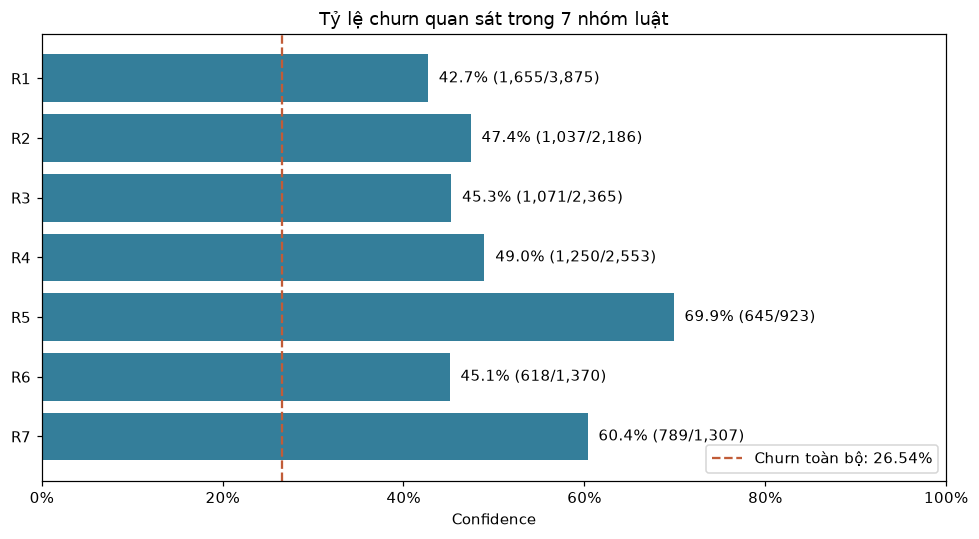

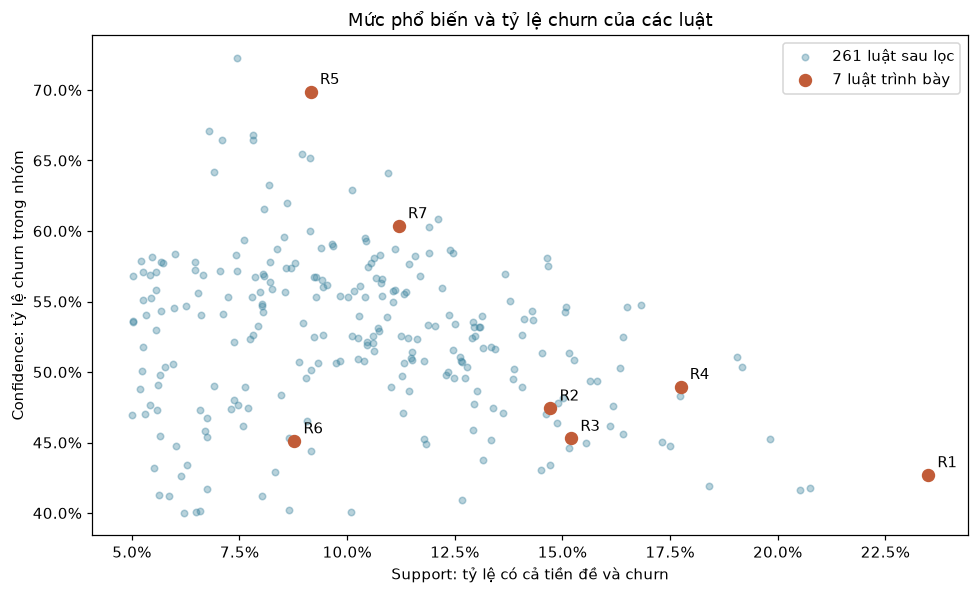

rule_id,R1,R2,R3,R4,R5,R6,R7
rule_id,,,,,,,
R1,3875,1994,1850,2165,916,975,1307
R2,1994,2186,978,1203,923,316,631
R3,1850,978,2365,1400,635,783,1307
R4,2165,1203,1400,2553,768,997,989
R5,916,923,635,768,923,316,631
R6,975,316,783,997,316,1370,638
R7,1307,631,1307,989,631,638,1307


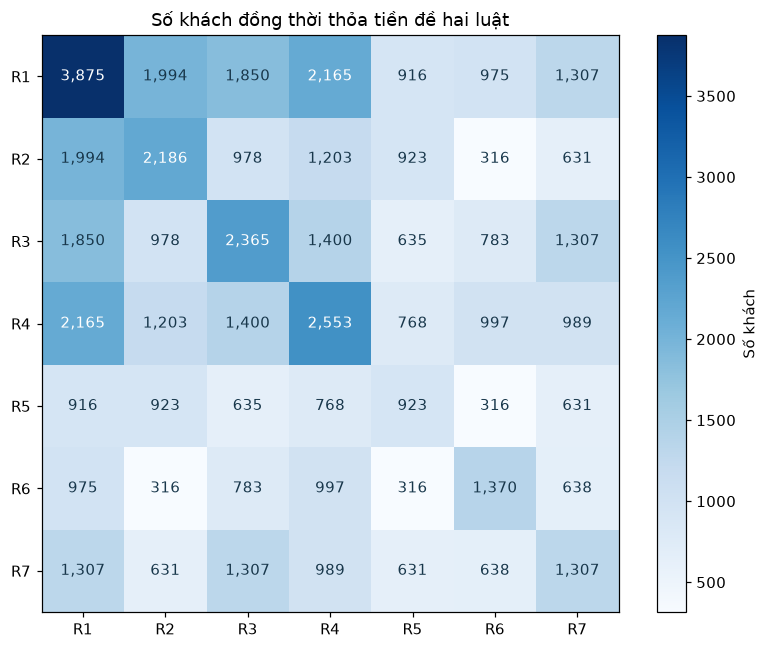

Cộng riêng kích thước 7 nhóm được 14,579 lượt khách, nhưng hợp các nhóm chỉ có 4,934 khách duy nhất (70.06% dữ liệu), trong đó 1,787 người churn. Đây là độ bao phủ mô tả trên mẫu, không phải recall của mô hình dự đoán.

In [5]:
fig, ax = plt.subplots(figsize=(9,5))
bars = ax.barh(featured["rule_id"], featured["confidence"],color="#347E9A")
ax.invert_yaxis()
ax.set_xlim(0,1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(title="Tỷ lệ churn quan sát trong 7 nhóm luật",xlabel="Confidence")
ax.axvline(BASE,color="#C15C38",linestyle="--",label=f"Churn toàn bộ: {BASE:.2%}")
for bar,row in zip(bars,featured.itertuples()):
    ax.text(row.confidence+.012,bar.get_y()+bar.get_height()/2,
            f"{row.confidence:.1%} ({int(row.n_churn_in_group):,}/{int(row.n_antecedent):,})",
            va="center",fontsize=10)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "08_featured_confidence.png",dpi=160)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(9,5.5))
ax.scatter(rules_05["support"],rules_05["confidence"],s=18,alpha=.35,
           color="#347E9A",label=f"{len(rules_05)} luật sau lọc")
ax.scatter(featured["support"],featured["confidence"],s=60,
           color="#C15C38",label="7 luật trình bày")
for row in featured.itertuples():
    ax.annotate(row.rule_id,(row.support,row.confidence),xytext=(6,5),
                textcoords="offset points",fontsize=10)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlabel="Support: tỷ lệ có cả tiền đề và churn",
       ylabel="Confidence: tỷ lệ churn trong nhóm",
       title="Mức phổ biến và tỷ lệ churn của các luật")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "09_support_confidence.png",dpi=160)
plt.show()
plt.close(fig)

masks = np.column_stack([customers_matching(a).to_numpy() for a in featured["antecedents"]])
intersections = masks.astype(np.int64).T @ masks.astype(np.int64)
assert np.array_equal(np.diag(intersections),featured["n_antecedent"].to_numpy())
overlap = pd.DataFrame(intersections,index=featured["rule_id"],columns=featured["rule_id"])
display(overlap)
overlap.to_csv(TABLE_DIR / "featured_rule_customer_overlap.csv",encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(7.5,6))
im = ax.imshow(intersections,cmap="Blues")
ax.set_xticks(range(len(featured)),featured["rule_id"])
ax.set_yticks(range(len(featured)),featured["rule_id"])
ax.set_title("Số khách đồng thời thỏa tiền đề hai luật")
for i in range(len(featured)):
    for j in range(len(featured)):
        ax.text(j,i,f"{intersections[i,j]:,}",ha="center",va="center",
                color="white" if intersections[i,j] > intersections.max()*.55 else "#18374B",fontsize=10)
fig.colorbar(im,ax=ax,label="Số khách")
fig.tight_layout()
fig.savefig(FIG_DIR / "10_rule_overlap.png",dpi=160)
plt.show()
plt.close(fig)

union = masks.any(axis=1)
unique_customers = int(union.sum())
unique_churn = int((union & clean["Churn"].eq("Yes").to_numpy()).sum())
overlap_explanation = (
    f"Cộng riêng kích thước 7 nhóm được {int(featured['n_antecedent'].sum()):,} lượt khách, "
    f"nhưng hợp các nhóm chỉ có {unique_customers:,} khách duy nhất "
    f"({unique_customers/N:.2%} dữ liệu), trong đó {unique_churn:,} người churn. "
    "Đây là độ bao phủ mô tả trên mẫu, không phải recall của mô hình dự đoán."
)
display(Markdown(overlap_explanation))

## 5. Độ nhạy của 7 luật và đề xuất có căn cứ

Luật còn đạt ở support 0,10 là luật phổ biến hơn trên cùng dữ liệu, chưa phải được xác nhận ngoài mẫu. Support của luật là tần suất tiền đề **và churn**, nên một nhóm có nhiều khách vẫn có thể không đạt nếu số churn trong nhóm chưa đủ.

Các đề xuất là hướng khảo sát và thử nghiệm. Chưa có dữ liệu để tính số churn sẽ giảm, doanh thu tăng hoặc hiệu quả một chương trình giữ chân.

In [6]:
sensitivity = pd.read_csv(TABLE_DIR / "apriori_support_sensitivity.csv")
display(sensitivity)
display(featured[["rule_id","support","qualified_at_support_10","selected_at_support_10"]])
sensitivity_explanation = (
    f"Ở support 0,05 có {len(rules_05)} luật sau lọc. "
    f"Khi tăng lên 0,10, còn {len(selected_10)} luật sau lọc. "
    f"Trong 7 luật trình bày, {int(featured['qualified_at_support_10'].sum())} luật còn đạt các ngưỡng "
    "trước lọc dư thừa. Hai mức support dùng cùng khách hàng và cùng mốc rời rạc hóa."
)
display(Markdown(sensitivity_explanation))
display(featured[["rule_id","suggestion","limitation"]])

,min_support,n_itemsets,n_target_rules,n_meeting_thresholds,n_selected,seconds
0,0.05,11604,659,530,261,1.010116
1,0.10,3717,221,195,137,0.290349


,rule_id,support,qualified_at_support_10,selected_at_support_10
0,R1,0.234985,True,True
1,R2,0.147238,True,True
2,R3,0.152066,True,True
3,R4,0.177481,True,True
4,R5,0.091580,False,False
5,R6,0.087747,False,False
6,R7,0.112026,True,True


Ở support 0,05 có 261 luật sau lọc. Khi tăng lên 0,10, còn 137 luật sau lọc. Trong 7 luật trình bày, 5 luật còn đạt các ngưỡng trước lọc dư thừa. Hai mức support dùng cùng khách hàng và cùng mốc rời rạc hóa.

,rule_id,suggestion,limitation
0,R1,Khảo sát lý do lựa chọn hợp đồng ngắn và mức h...,Khách chưa hài lòng có thể tự chọn hợp đồng ng...
1,R2,"Khảo sát trải nghiệm đăng ký, lắp đặt và sử dụ...","Tenure là thời lượng trong ảnh chụp dữ liệu, c..."
2,R3,Khảo sát khó khăn và mức hài lòng với phương t...,Phương thức thanh toán có thể đi kèm loại hợp ...
3,R4,"Khảo sát nhu cầu hỗ trợ và bảo mật, kiểm tra c...",Không đăng ký dịch vụ không đồng nghĩa đã gặp ...
4,R5,"Khảo sát trải nghiệm lắp đặt, chất lượng và kỳ...",Nhóm con của R2; chênh lệch chưa kiểm soát hợp...
5,R6,"Tìm hiểu giá trị cảm nhận, nhu cầu hỗ trợ và k...","High là nhóm phí trên phân vị 2/3 của mẫu, khô..."
6,R7,"Khảo sát đồng thời chất lượng dịch vụ, điều kh...",Chồng lấn R1/R3 và có thể chồng lấn các luật k...


## 6. Bài học để bảo vệ

### Quy trình và vai trò từng notebook
1. Notebook 1: kiểm tra dữ liệu gốc, làm sạch, mô tả tỷ lệ và so sánh nhóm.
2. Notebook 2: biến đặc điểm thành mục giao dịch, tìm tập mục phổ biến, sinh luật, lọc và kiểm tra bằng đếm.
3. Notebook 3: chọn luật dễ giải thích, kiểm tra chồng lấn, trình bày nhận xét và gợi ý cần kiểm chứng.

### Apriori hoạt động như thế nào?
Đếm từng mục để tìm L1. Ghép các mục phổ biến để tạo ứng viên hai mục, đếm và giữ L2. Tiếp tục ba rồi bốn mục. Nếu một tập con không phổ biến, bỏ ứng viên lớn hơn chứa nó vì support không thể tăng khi thêm điều kiện. Từ các tập phổ biến, sinh luật và tính confidence/lift; trong bài chỉ giữ hệ quả Churn=Yes.

Ví dụ ba khách có A, trong đó hai khách có A và B: support(A và B) không thể lớn hơn support(A). Nguyên lý này giúp giảm số tổ hợp phải đếm. Thư viện thực hiện thuật toán; khi bảo vệ vẫn cần hiểu cơ chế.

### Mã hóa khác lựa chọn đặc trưng thế nào?
Chọn 14 biến là giới hạn phạm vi bằng ý nghĩa và khả năng diễn giải, chưa khẳng định đó là các biến quan trọng nhất. One-hot biến mỗi trạng thái thành một mục để đếm giao dịch, không đánh giá độ quan trọng của biến.

### Vì sao 15 biến thành 42 mục?
14 biến đầu vào cộng Churn là 15 biến. Mỗi biến có nhiều mức, mỗi mức thành một cột Boolean. Một khách có đúng một mức mỗi biến nên có 15 mục True trong 42 cột, không phải có 42 đặc điểm cùng lúc.

### Vì sao không chuẩn hóa hoặc SMOTE?
Apriori đếm sự có mặt của mục; số liên tục đã chia nhóm nên không cần StandardScaler. Sinh khách tổng hợp sẽ thay tần suất dữ liệu, làm support và tỷ lệ nền không còn mô tả khách thật ban đầu.

### Có mâu thuẫn với yêu cầu không ML không?
Bài dùng khai phá luật kết hợp, không huấn luyện bộ phân loại churn. Apriori đôi khi được xếp trong học không giám sát; phạm vi cần được giảng viên chấp nhận. Không gọi Apriori là thuật toán hoàn toàn ngoài ML theo mọi cách phân loại.

### Vì sao chọn support 0,05, confidence 0,40, lift 1,5?
Support 0,05 yêu cầu ít nhất 353 khách có cả tiền đề và churn trên 7.043 khách. Confidence 0,40 yêu cầu tỷ lệ churn trong nhóm từ 40%. Lift 1,5 yêu cầu tỷ lệ này bằng ít nhất 1,5 lần nền khoảng 26,5%. Các ngưỡng là lựa chọn thực nghiệm, kèm so sánh support 0,10; không có một ngưỡng chuẩn cho mọi bài.

### Luật A → churn có nghĩa tất cả khách A sẽ churn không?
Không. Confidence dưới 100% cho thấy vẫn có khách A không churn. Bài mô tả tỷ lệ trong dữ liệu, không cam kết xác suất tương lai cho từng khách.

### Lift 2 có nghĩa churn tăng 200% không?
Không. Nó nghĩa tỷ lệ nhóm bằng hai lần tỷ lệ nền; nếu diễn đạt tương đối thì cao hơn nền 100%. Phân biệt tỷ số với chênh lệch điểm phần trăm.

### Tại sao không nói nguyên nhân?
Các đặc điểm được quan sát cùng nhau; có thể có yếu tố khác tác động đồng thời. Chưa có thử nghiệm can thiệp hoặc thiết kế nghiên cứu để kết luận một thay đổi làm giảm churn.

### Tại sao không gọi luật là có ý nghĩa thống kê?
Bài chưa kiểm định giả thuyết hoặc hiệu chỉnh việc tìm nhiều luật. Support/confidence/lift là chỉ số mô tả, không thay thế p-value. Không khẳng định khác biệt ở nhóm con là có ý nghĩa thống kê.

### Làm sao biết tính toán đúng?
Kiểm tra điểm biên của nhóm, đúng một mục cho mỗi biến; ví dụ giao dịch nhỏ có đáp án tính tay; đếm lại mọi luật mục tiêu ở Notebook 2; đọc lại dữ liệu bàn giao và đối chiếu 261 luật trong Notebook 3.

### Hạn chế cần nói
Dữ liệu dạng ảnh chụp, kết quả phụ thuộc biến và mốc nhóm đã chọn, các luật được tìm và mô tả trên cùng mẫu, nhóm có thể chồng lấn, ngưỡng mang tính thực nghiệm. Chưa có bằng chứng nhân quả, hiệu quả kinh doanh hay tổng quát hóa ngoài mẫu.

### Dàn ý nói trong khoảng 3 phút
- Mục tiêu: tìm tổ hợp đặc điểm liên quan đến churn bằng Apriori.
- Nguồn và tiền xử lý: 7.043 khách, xử lý TotalCharges trống, bỏ ID, giữ tỷ lệ churn thực.
- Chuẩn bị giao dịch: 14 biến, rời rạc hóa tenure/phí tháng, thêm Churn, 42 mục Boolean.
- Thuật toán: giải thích support/confidence/lift, ngưỡng và nguyên lý tập con.
- Kết quả: số luật trước/sau lọc, trình bày R5 với số khách và ba phép tính.
- Kết luận: nhóm nào đáng khảo sát, các đề xuất cần kiểm chứng và giới hạn.

**Cách tự học:** che bảng chỉ số, tự tính R5 từ số khách; giải thích confidence bằng một câu; sau đó giải thích vì sao support có mẫu số khác. Khi làm được mới học phần lọc luật và chồng lấn.

## 7. Xuất bảng trình bày và báo cáo học tập
Báo cáo Markdown gồm số liệu vừa tính, 7 diễn giải, ví dụ tính tay và phần ôn tập. Có thể dùng làm nguồn soạn Word/slide về sau; đây chưa phải file Word hay PowerPoint.

In [7]:
export = featured.copy()
for column in ["antecedents","consequents"]:
    export[column] = export[column].map(lambda s: json.dumps(sorted(s),ensure_ascii=False))
export.to_csv(TABLE_DIR / "apriori_featured_rules.csv",index=False,encoding="utf-8-sig")
display_table = "| Luật | Nhóm | Khách | Churn | Support | Confidence | Lift |\n|---|---|---:|---:|---:|---:|---:|\n"
for row in featured.itertuples():
    display_table += (f"| {row.rule_id} | {row.title} | {int(row.n_antecedent):,} | "
                      f"{int(row.n_churn_in_group):,} | {row.support:.2%} | {row.confidence:.2%} | {row.lift:.2f} |\n")
# Văn bản ôn tập nằm nguyên trong cell Markdown, để báo cáo và notebook thống nhất.
import nbformat
notebook_path = ROOT / "notebooks/apriori/03_rule_interpretation.ipynb"
source_notebook = nbformat.read(notebook_path,as_version=4)
learning_text = next(cell.source for cell in source_notebook.cells
                     if cell.cell_type == "markdown" and cell.source.startswith("## 6."))
report = (
    "# Khai phá luật kết hợp Telco Customer Churn — Báo cáo và hướng dẫn học\n\n"
    f"Phân tích {N:,} khách; {int(clean['Churn'].eq('Yes').sum()):,} khách churn ({BASE:.2%}).\n\n"
    "## Dữ liệu và phương pháp\n\n"
    "Chạy ba notebook riêng theo thứ tự 01→03. Xử lý 11 TotalCharges trống sau kiểm tra tenure=0, "
    "bỏ customerID khỏi khai phá và giữ mọi khách. Dùng 12 biến phân loại, hai biến nhóm, thêm Churn. "
    "Tenure: 0–12, 13–24, 25–48, >48. Mốc phí tháng (min, phân vị 1/3, phân vị 2/3, max): "
    + str(run['binning']['monthly_charges']['edges']) + ". Các khoảng: [min,q1], (q1,q2], (q2,max]. "
    "Ma trận có " + str(run['n_items']) + " mục và 15 mục True trên mỗi khách.\n\n"
    "Apriori: support 0,05; confidence 0,40; lift 1,5; tập mục tối đa 4, tiền đề tối đa 3; "
    "hệ quả đúng Churn=Yes. Lọc thông tin cấu trúc lặp và luật thêm điều kiện có confidence tăng "
    "không quá 2 điểm phần trăm so với luật ngắn được giữ. Giữ bảng đầy đủ để đối chiếu.\n\n"
    "## Bảy luật trình bày\n\n" + display_table + "\n"
    "Lựa chọn theo chủ đề và khả năng diễn giải; không khẳng định đứng đầu mọi tiêu chí.\n\n"
    + "\n".join(narratives) + "\n## Ví dụ tính tay\n\n" + example_explanation
    + "\n\n" + hand.to_string(index=False) + "\n\n## Độ nhạy và chồng lấn\n\n"
    + sensitivity_explanation + "\n\n" + overlap_explanation
    + "\n\n![Confidence](figures/08_featured_confidence.png)\n\n"
    "![Support và confidence](figures/09_support_confidence.png)\n\n"
    "![Khách chồng lấn](figures/10_rule_overlap.png)\n\n"
    + learning_text + "\n\n## Tài liệu\n\n"
    "- Nguồn cục bộ: data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv; SHA256: "
    + cleaning["source_sha256"] + "\n"
    "- [Apriori — mlxtend](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/apriori/)\n"
    "- [Association rules — mlxtend](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/association_rules/)\n"
)
report_path = REPORT_DIR / "apriori_report_and_study_guide.md"
report_path.write_text(report,encoding="utf-8")
saved = pd.read_csv(TABLE_DIR / "apriori_featured_rules.csv")
assert len(saved) == 7 and saved["rule_id"].is_unique
assert np.allclose(saved["confidence"],featured["confidence"])
assert hashlib.sha256((DATA_DIR / "telco_clean.csv").read_bytes()).hexdigest() == run["clean_sha256"]
print("Bảng 7 luật:", TABLE_DIR / "apriori_featured_rules.csv")
print("Báo cáo học tập:", report_path)
print("Kiểm tra xong: giao dịch đúng nguồn, số liệu các luật, phép tính R5, số khách không đếm lặp.")

Bảng 7 luật: D:\vu\hoctap\Telco-Churn-Apriori\reports\apriori\tables\apriori_featured_rules.csv
Báo cáo học tập: D:\vu\hoctap\Telco-Churn-Apriori\reports\apriori\apriori_report_and_study_guide.md
Kiểm tra xong: giao dịch đúng nguồn, số liệu các luật, phép tính R5, số khách không đếm lặp.
